<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Метод главных компонент</span></h2>




Метод главных компонент это статистический метод, который используется для уменьшения размерности данных, сохраняя при этом как можно больше информации.

Основная идея PCA заключается в том, чтобы преобразовать исходные переменные в новый набор некоррелированных переменных, которые называются *главными компонентами*. Главные компоненты создаются так, чтобы первая компонента объясняла наибольшую долю дисперсии исходных данных, вторая — следующую по величине долю и так далее. Сжатое представление данных в виде главных компонент может быть использовано для визуализации многомерных данных, для кластеризации, в качестве входных данных для других методов машинного обучения или для других аналитических целей. Подробнее теорию метода можно посмотреть в презентации с лекции. 

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as sps
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from tqdm.auto import tqdm

from notebook_pca_tools import (
    plot_projected_images,
    plot_projection_scatter,
    visualize_decompress_images,
    visualize_main_components,
    visualize_projection_images,
)

RANDOM_STATE = 42
sns.set_theme(style="darkgrid", palette="Set2")

> #### Реализация PCA из sklearn
> 
> <a href="https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA" target="_top">`sklearn.decomposition.PCA`</a>`(n_components=None)`
> 
> Самый важный параметр: 
> * `n_components` &mdash; размерность сжатого пространства, иными словами количество главных компоненты.
> 
> Методы класса:
> * `fit(X)` &mdash; обучиться на данных `X`;
> * `transform(X_new)` &mdash; вернуть сжатое представление `X_new` для обученной ранее модели;
> * `fit_transforn(X)` &mdash; обучиться на данных `X` и вернуть сжатое представление `X`;
> * `inverse_transform(Y)` &mdash; восстановить сжатые данные `Y` в исходное пространство.
> 
> Атрибуты класса:
> 
> * `components_` &mdash; главные компоненты в порядке убывания доли объясненной дисперсии (собственных чисел), размер `(n_components, n_features)`;
> * `explained_variance_` &mdash; дисперсия вдоль главных компонент, равны собственным числам, размер `(n_components,)`;
> * `explained_variance_ratio_` &mdash; доля дисперсии, объясняемая каждой компонентой, размер `(n_components,)`;
> * `mean_` &mdash; среднее по данным, размер `(n_features,)`.


## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1</span> <span style="color:inherit;">Простой пример</span>

Вначале рассмотрим самый простой пример: отобразим двумерные данные в одномерное пространство, а затем применим обратное преобразование

Сгенерируем 100 точек в двумерном пространстве и визуализируем их

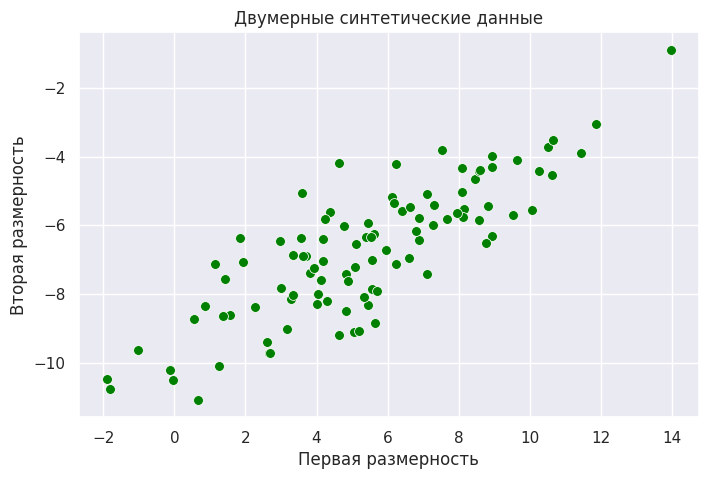

In [2]:
sample_size = 100  # Размер выборки
sample = sps.multivariate_normal(mean=[5, -7], cov=[[13, 7], [7, 5]]).rvs(
    sample_size, random_state=RANDOM_STATE
)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=sample[:, 0], y=sample[:, 1], s=50, c="g")
plt.title("Двумерные синтетические данные")
plt.xlabel("Первая размерность")
plt.ylabel("Вторая размерность")
plt.show()

Применим PCA для отображения в одномерное пространство (`n_components=1`)

Направления главных компонент в исходном пространстве (одной компоненты): [[0.87  0.494]]
Среднее по данным: [ 5.396 -6.732] == [ 5.396 -6.732]
Размерность проекции: (100, 1)


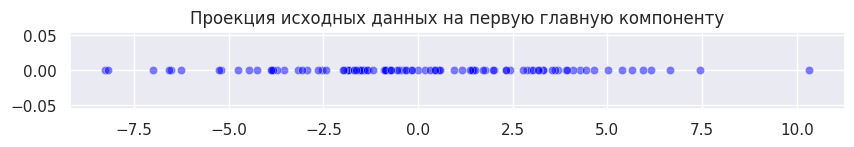

In [3]:
# Обучаем и тут же применяем PCA
pca = PCA(n_components=1)
sample_projection = pca.fit_transform(sample)

print(
    f"Направления главных компонент в исходном пространстве (одной компоненты): {pca.components_.round(3)}"
)
print(f"Среднее по данным: {pca.mean_.round(3)} == {sample.mean(axis=0).round(3)}")
print(f"Размерность проекции: {sample_projection.shape}")

# Визуализируем на числовой прямой проекцию после применения PCA
plt.figure(figsize=(10, 1))
sns.scatterplot(x=sample_projection[:, 0], y=0, c="b", alpha=0.5)
plt.title("Проекция исходных данных на первую главную компоненту")
plt.show()

Теперь применим обратное преобразование и визуализируем вместе с исходными точками

In [4]:
sample_reprojection = pca.inverse_transform(sample_projection)
print(f"Размерность репроекции в исходное пространство: {sample_reprojection.shape}")

Размерность репроекции в исходное пространство: (100, 2)


Визуализируем результат вместе с исходными точками

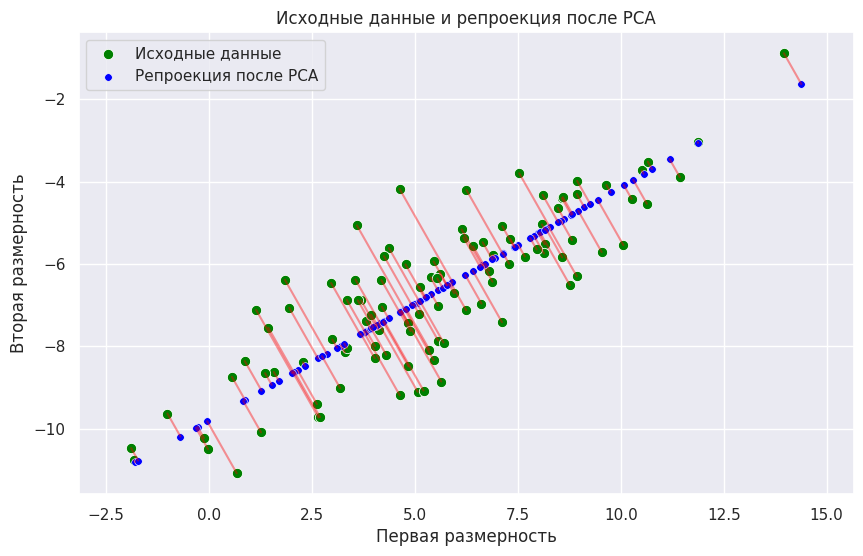

In [5]:
plt.figure(figsize=(10, 6))

# Рисуем отрезки, соединяющие исходную точку и ее образ
for point, reproj in zip(sample, sample_reprojection):
    plt.plot([point[0], reproj[0]], [point[1], reproj[1]], c="red", alpha=0.4)

# Рисуем исходные точки
sns.scatterplot(
    x=sample[:, 0], y=sample[:, 1], s=55, c="green", label="Исходные данные"
)
# Рисуем восстановленные точки
sns.scatterplot(
    x=sample_reprojection[:, 0],
    y=sample_reprojection[:, 1],
    s=30,
    c="blue",
    label="Репроекция после PCA",
)

plt.axis("equal")  # Включаем одинаковый масштаб по осям, чтобы увидеть прямой угол
plt.title("Исходные данные и репроекция после PCA")
plt.xlabel("Первая размерность")
plt.ylabel("Вторая размерность")
plt.show()

Можно заметить несколько интересных моментов:
- Восстановленные данные лежат на одной прямой. Это объясняется линейностью обратного преобразования, а прямые (в частности любые одномерные данные) всегда переходят в прямые при линейном отображении.
- Отрезки соединяющие исходные точки и их восстановленные образы перпендикулярны прямой с образами. Так происходит, потому что PCA стремится максимизировать дисперсию вдоль первой главной компоненты, а значит минимизировать дисперсию (расстояние между точкой и образом) в нормальном направлении к этой прямой.

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2</span> <span style="color:inherit;">PCA для сжатия датасетов изображений лиц</span>

Изображения можно рассматривать как большие многомерные вектора. Попробуем применить к ним PCA.


Для начала загрузим <a href="https://thetahat.ru/files/ad/main/7/train_faces.npy" target="_top">датасет</a> фотографий человеческих лиц. В нем $280$ изображений, каждое размера $32 \times 32$ пикселя, то есть размерность одного вектора $1024$.

Размерность faces: (280, 1024)


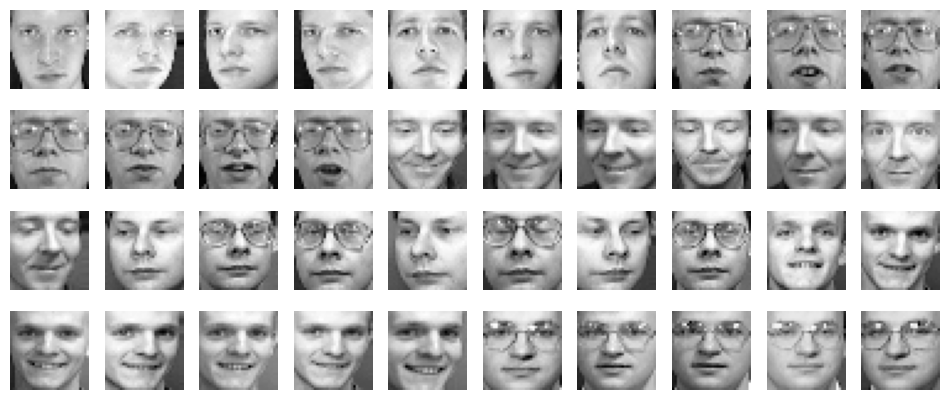

In [6]:
faces = np.loadtxt("data/train_faces.npy")
print(f"Размерность faces: {faces.shape}")

# Визуализируем несколько примеров из датасета
plt.figure(figsize=(12, 5))
for i in range(40):
    plt.subplot(4, 10, i + 1)
    plt.imshow(faces[i].reshape((32, 32)), cmap="gray")
    plt.axis("off")

Сделаем проекцию из исходного 1024-мерного пространства в 50-мерное с помощью PCA. Таким образом все изображения разложатся в сумму среднего и линейной комбинации из 50-ти изображений, являющихся первыми 50-тью главными компонентами.

In [7]:
pca = PCA(n_components=50)
faces_projection = pca.fit_transform(faces)
print(f"Размерность проекции: {faces_projection.shape}")

Размерность проекции: (280, 50)


Отобразим данные в проекции на первые две главные компоненты, также цветом отобразим третью главную компоненту

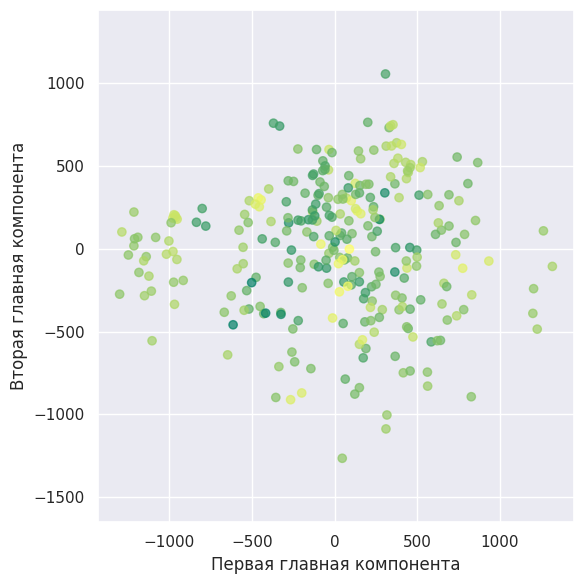

In [9]:
plot_projection_scatter(faces_projection)

Тот же самый график, но вместо точек визуализируем сами исходные объекты

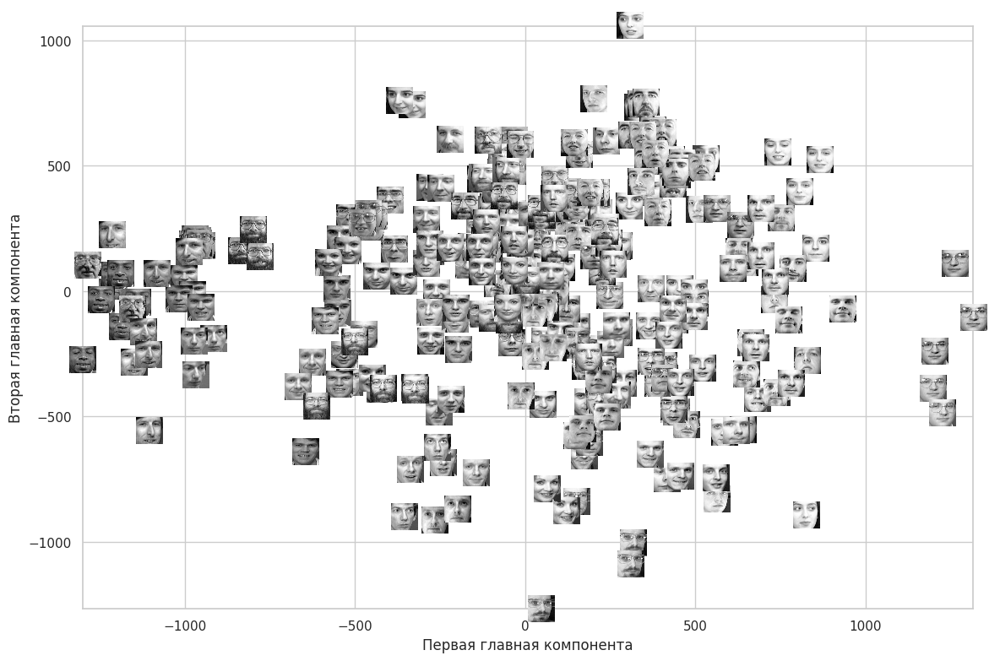

In [10]:
plot_projected_images(faces, faces_projection, shape=(32, 32), zoom=0.7, cmap="gray")

Визуализируем главные компоненты (по сути базисы, на которые разложилось каждое изображение):

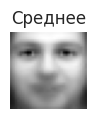

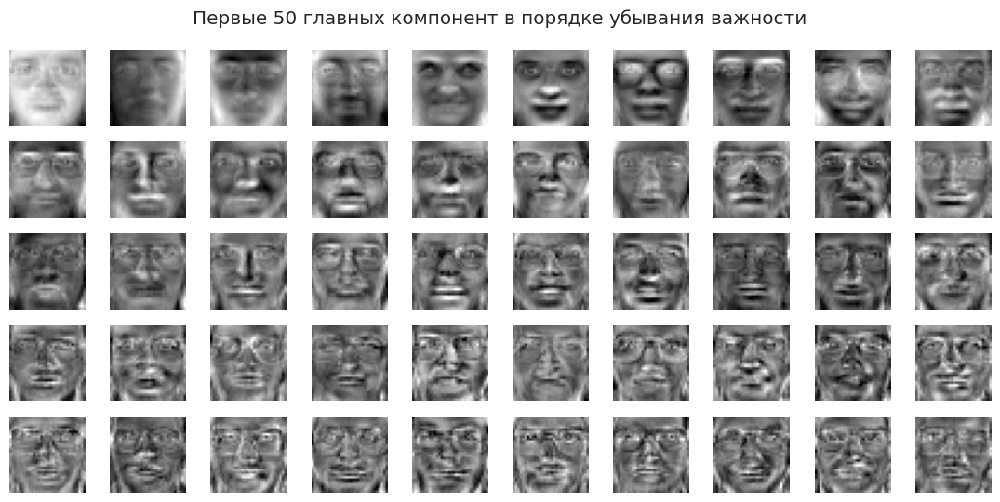

In [11]:
visualize_main_components(pca, num_components=50)

Как видно, на всех основных элементах прослеживаются очертания лиц. При этом если в первых элементах черты лица размыты и границы нечеткие, то в последних, наоборот, выделяются различные детали. То есть сначала видны общие черты лица: контур, поворот головы, глаза, а затем более мелкие детали: форма губ, бровей, очки и так далее.

Теперь для нескольких примеров изображений посмотрим с каким весом в них входит каждая главная компонента. Ниже 
* в первой колонке изображено исходное лицо, 
* во второй его приближение (проекция на первые 10 главных компонент),
* в третьей колонке среднее лицо, 
* в следующих 10 колонках первые 10 главных компонент, над которыми указаны коэффициенты, с которыми они входят в приближаемое лицо.

Стоит отметить, что все компоненты нормированы, однако при отрисовке они растягиваются до диапазона $[0, 255]$. Поэтому коэффициенты относятся не к изображениям компонент, а к самим нормированным компонентам.

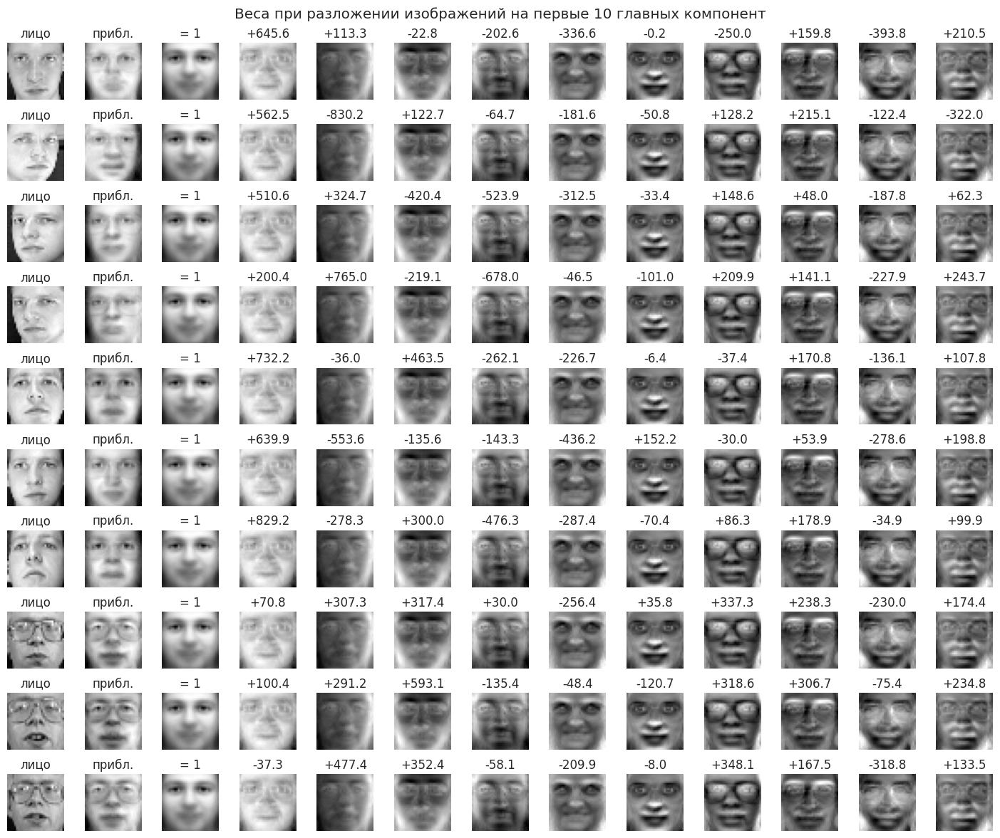

In [12]:
faces_pca = PCA(n_components=10)
faces_pca_projection = faces_pca.fit_transform(faces)
faces_pca_reprojection = faces_pca.inverse_transform(faces_pca_projection)

visualize_projection_images(
    faces,
    n_components=10,
    num_images=10,
    image_shape=(32, 32),
    pca=faces_pca,
    projection=faces_pca_projection,
    reprojection=faces_pca_reprojection,
)


Проведем эксперимент: переберем несколько значений `n_components` (количество главных компонент), для каждого обучим PCA, сделаем последовательно прямое и обратное преобразования, а затем визуально сравним полученные изображения с исходным.

100%|█████████████████████████████████████████████| 9/9 [00:03<00:00,  2.29it/s]


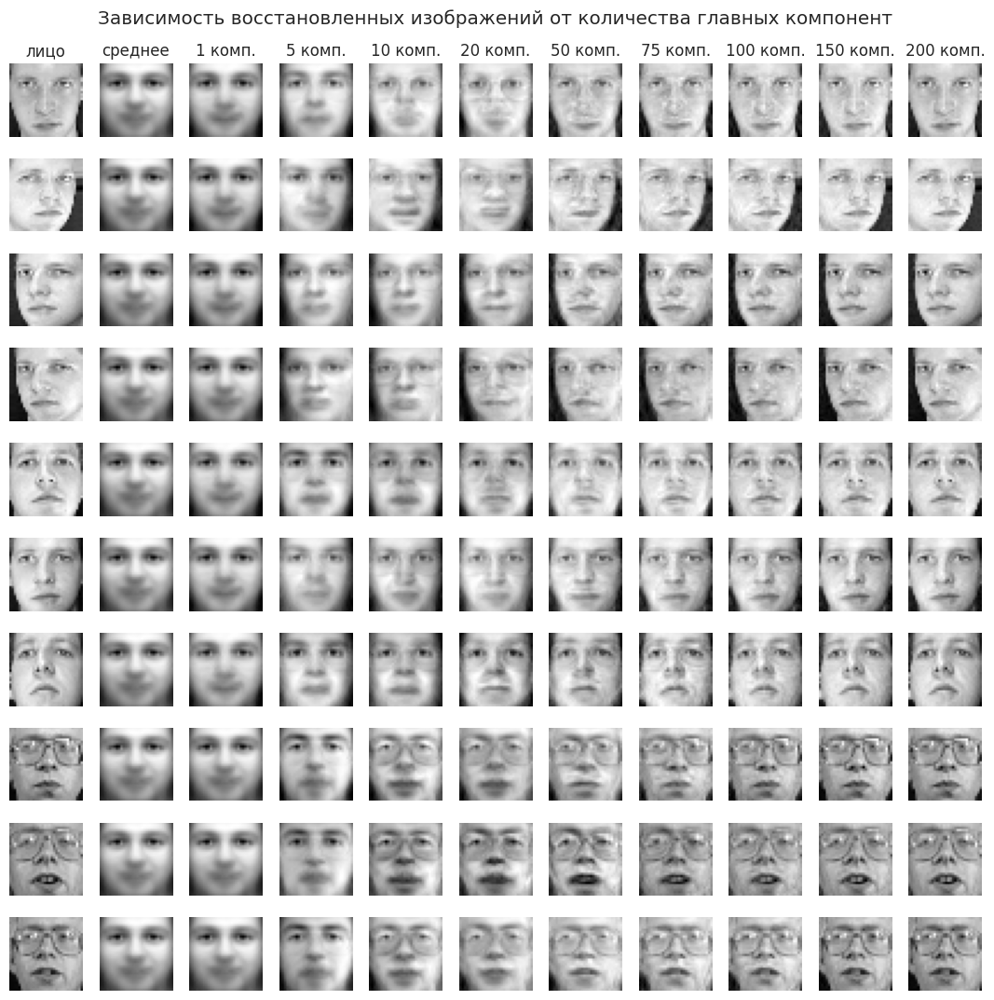

In [13]:
n_components_grid = [1, 5, 10, 20, 50, 75, 100, 150, 200]
faces_reprojections = {}

# Применяем PCA-проекцию и делаем восстановление
for n_components in tqdm(n_components_grid):
    faces_pca = PCA(n_components=n_components)
    faces_pca_projection = faces_pca.fit_transform(faces)
    faces_reprojections[n_components] = faces_pca.inverse_transform(
        faces_pca_projection
    )

faces_reprojections = visualize_decompress_images(
    faces,
    n_components_grid=n_components_grid,
    num_images=10,
    image_shape=(32, 32),
    pca=faces_pca,
    reprojections=faces_reprojections,
)

Можем заметить, что чем больше главных компонент мы задействуем, тем более детализированным становится изображение. Если использовать всего одну компоненту, можно воссоздать лишь общий контур человеческого лица. Если задействовать пять компонент, то станут видны некоторые особенности лица, например, поворот. Если использовать десять компонент, то можно различить формы глаз. А если использовать пятьдесят компонент, то уже можно увидеть очки.

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">3</span> <span style="color:inherit;">PCA для сжатия датасетов изображений котиков</span>


Как видно уже для 150 главных компонент разница между оригиналом и восстановленным изображением визуально почти незаметна.

Однако черно-белые маленькие изображения уж слишком игрушечный пример. Посмотрим на более интересный датасет котиков. В нем более $15\:000$ цветных фотографий размером $64 \times 64$, то есть им соответствует вектор размера $3 \cdot 64 \cdot 64 = 12\:288$.

Загрузим <a href="https://thetahat.ru/files/ad/main/7/cats.zip" target="_top">датасет</a> и посмотрим несколько примеров.

Размерность cats: (15747, 12288)


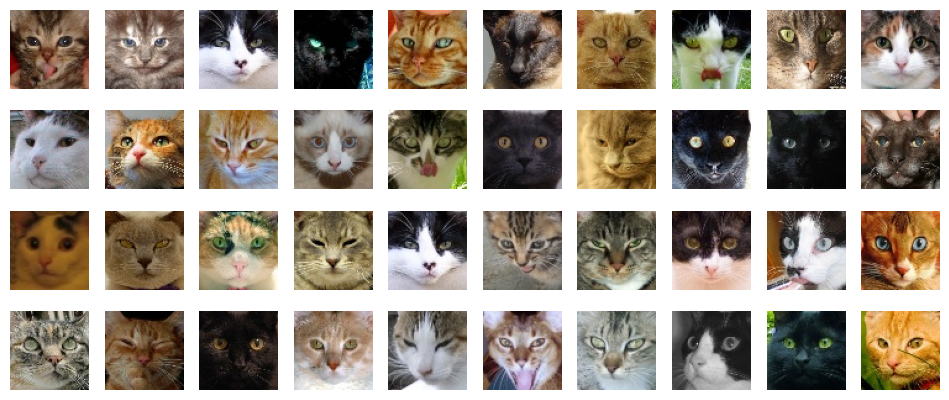

In [14]:
cats_path = "data/cats"
cats = []

for filename in os.listdir(cats_path):
    cats.append(plt.imread(os.path.join(cats_path, filename)))

cats = np.stack(cats).reshape(-1, 64 * 64 * 3)
print(f"Размерность cats: {cats.shape}")

# Визуализируем примеры
plt.figure(figsize=(12, 5))
for i in range(40):
    plt.subplot(4, 10, i + 1)
    plt.imshow(cats[i].reshape(64, 64, 3))
    plt.axis("off")

Также как и ранее посмотрим на изображения, соответствующие первым 70 главным компонентам

In [15]:
pca = PCA(n_components=100)
cats_projection = pca.fit_transform(cats.astype(np.float32))
print(f"Размерность проекции: {cats_projection.shape}")

Размерность проекции: (15747, 100)


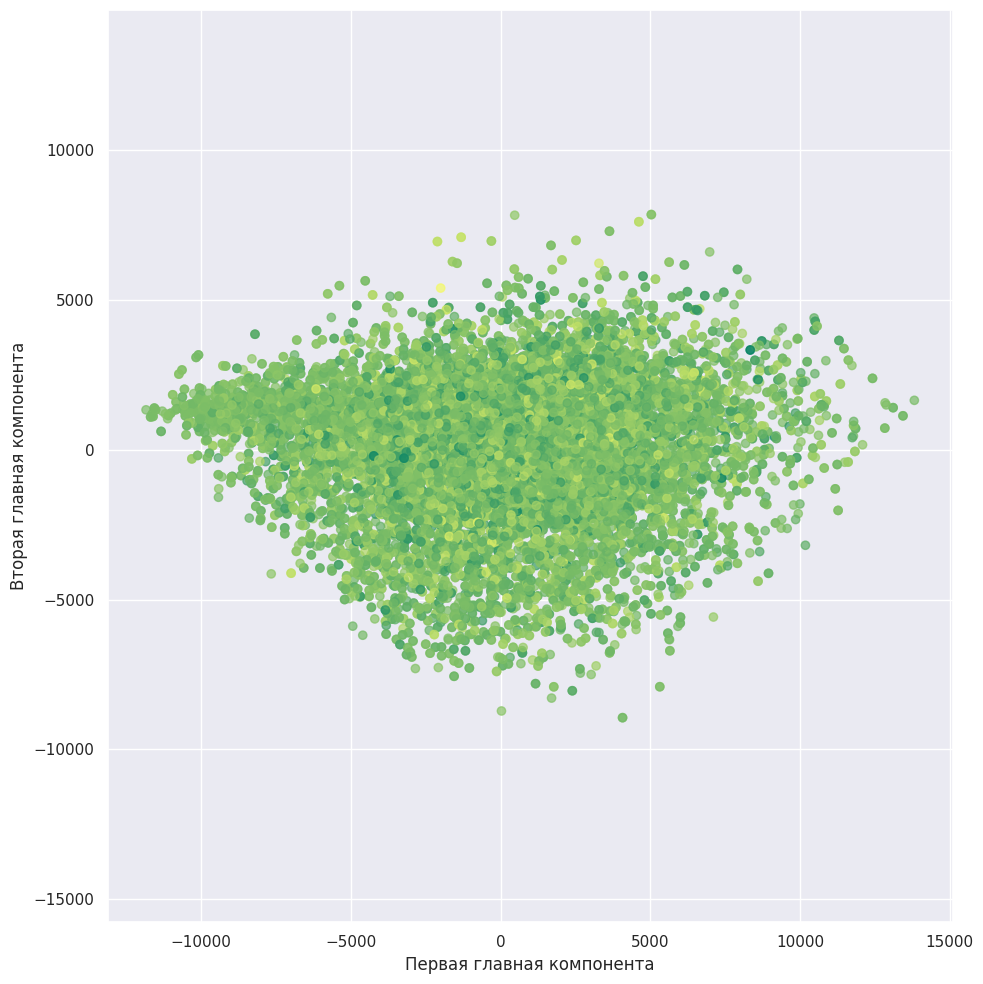

In [16]:
plot_projection_scatter(cats_projection, figsize=(10, 10))

Тот же самый график, но вместо точек визуализируем сами исходные изображения

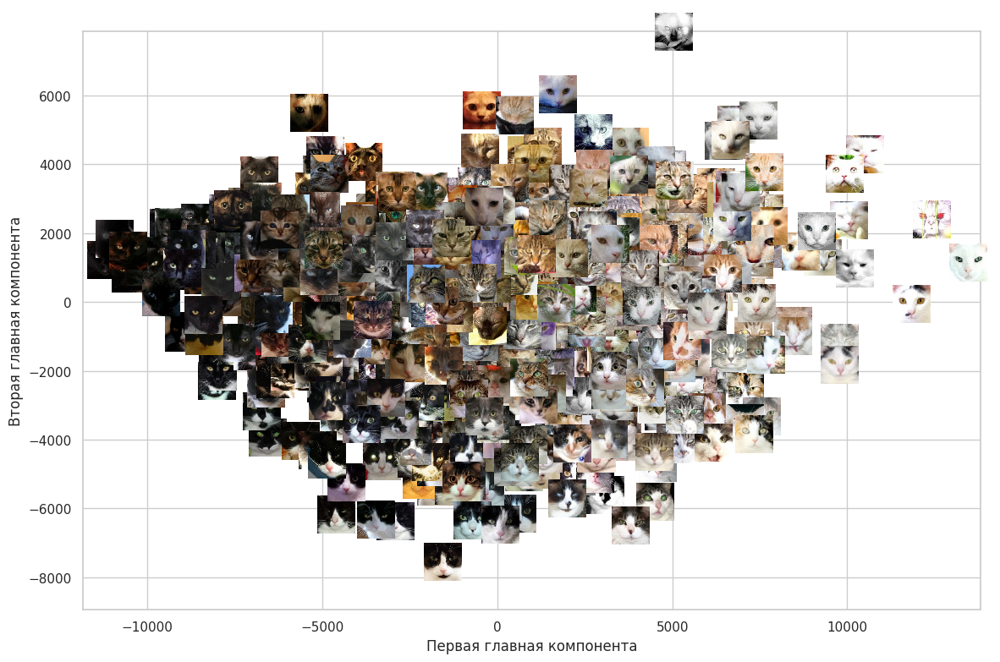

In [17]:
plot_projected_images(cats, cats_projection, shape=(64, 64, 3), zoom=0.5, n_images=1000)

Отобразим также первые 70 главных компонент

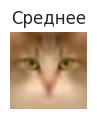

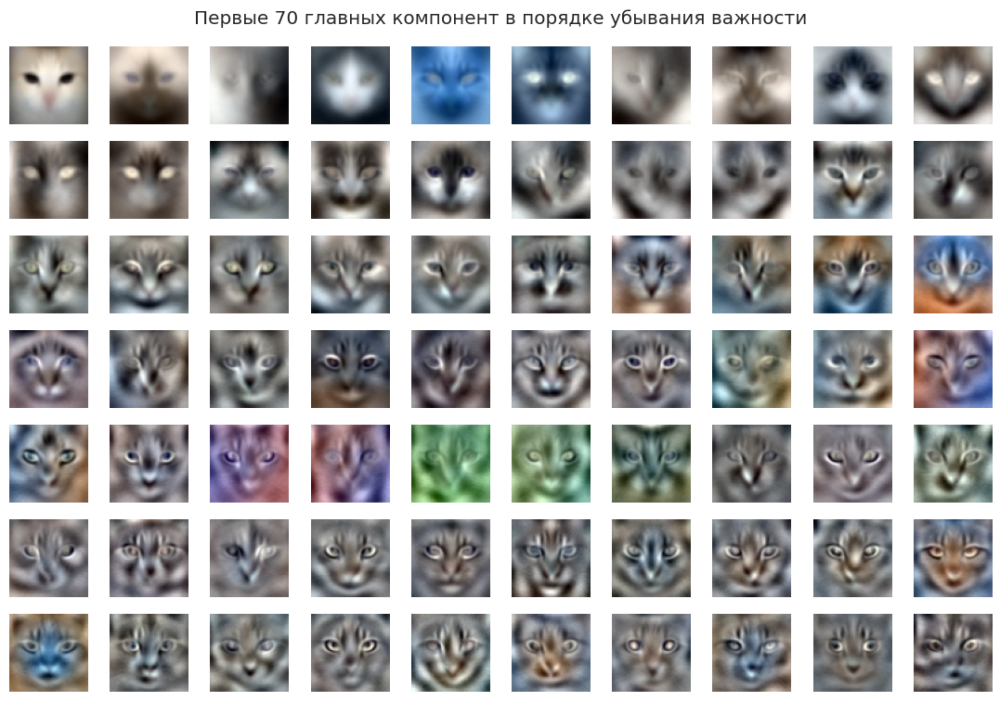

In [18]:
visualize_main_components(pca, num_components=70, image_shape=(64, 64, 3))

Как и в случае с лицами, на первом этапе мы видим размытые очертания, которые формируют общую форму кошачьей мордочки, повороты головы и общие черты глаз. Затем появляются более детальные изображения, включая цвет шерсти, пятнышки, усы и другие детали.

Теперь посмотрим с какими коэффициентами входят первые 10 главных компонент в изображение

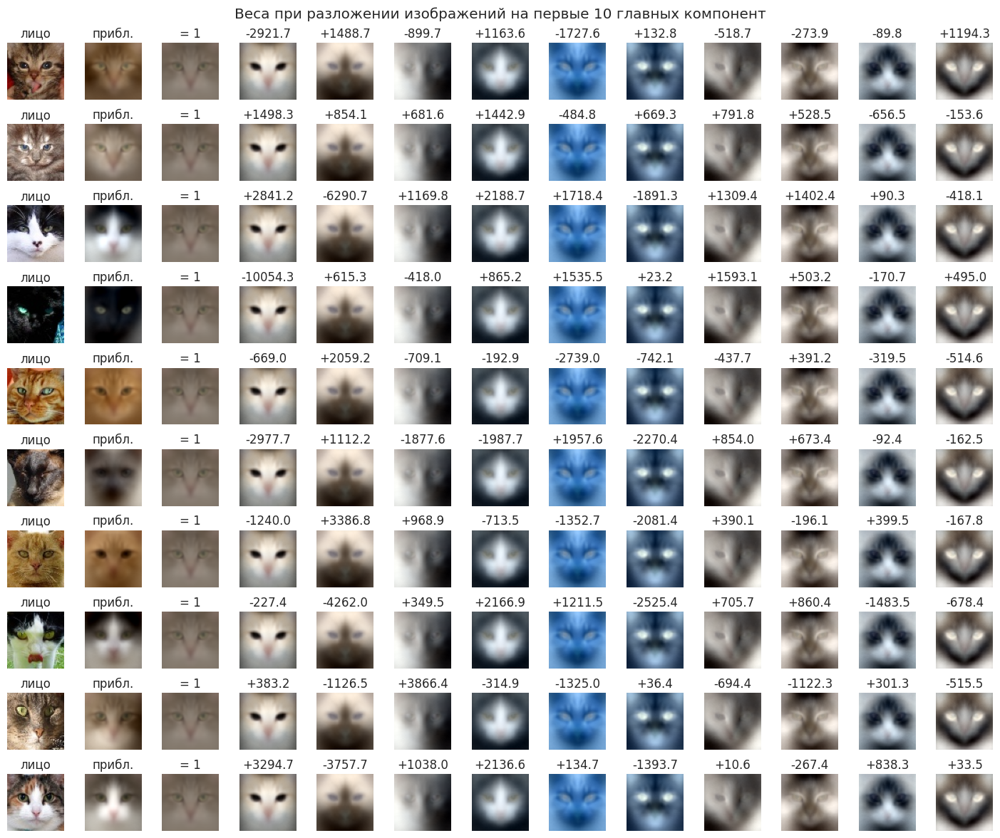

In [19]:
cats_pca = PCA(n_components=10)
cats_pca_projection = cats_pca.fit_transform(cats)
cats_pca_reprojection = cats_pca.inverse_transform(cats_pca_projection)

visualize_projection_images(
    cats,
    n_components=10,
    num_images=10,
    image_shape=(64, 64, 3),
    pca=cats_pca,
    projection=cats_pca_projection,
    reprojection=cats_pca_reprojection,
)

Также посмотрим на качество восстановленных изображений в зависимости от числа главных компонент.

100%|█████████████████████████████████████████████| 9/9 [10:12<00:00, 68.06s/it]


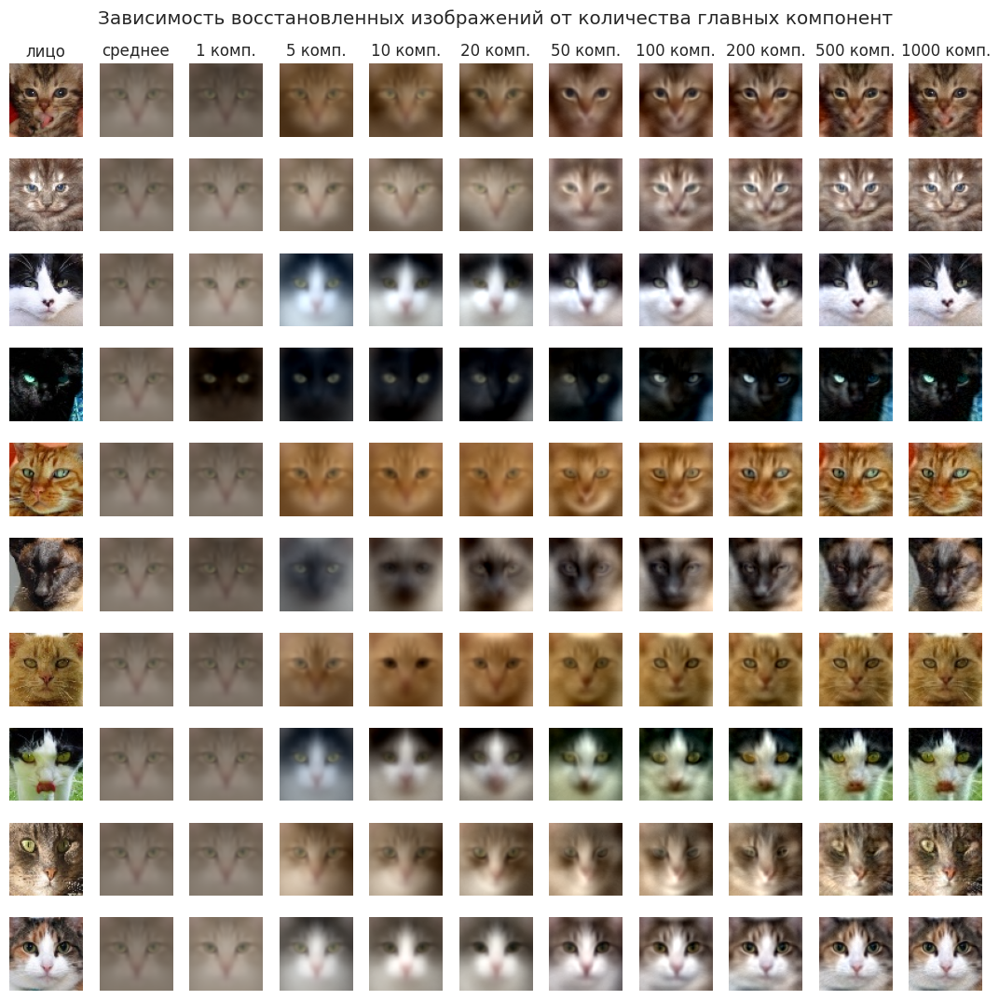

In [20]:
n_components_grid = [1, 5, 10, 20, 50, 100, 200, 500, 1000]
cats_reprojections = {}

# Применяем PCA-проекцию и делаем восстановление
for n_components in tqdm(n_components_grid):
    cats_pca = PCA(n_components=n_components)
    cats_pca_projection = cats_pca.fit_transform(cats)
    cats_reprojections[n_components] = cats_pca.inverse_transform(
        cats_pca_projection
    )

cats_reprojections = visualize_decompress_images(
    cats,
    n_components_grid=n_components_grid,
    num_images=10,
    image_shape=(64, 64, 3),
    pca=cats_pca,
    reprojections=cats_reprojections,
)

Видим, что уже для 500 главных компонент восстановленные изображения почти не отличаются от оригинальных.

Оценим во сколько раз можно уменьшить размер данного датасета при сжатии в 500-мерное пространство.

Пусть всего $n$ изображений размерности $D$ и делается проекция на $d$ главных компонент, тогда:
- каждое изображение представляется вектором размерности $d$ из `float32`, всего изображений $n$; получаем $4dn$ байт;
- $d$ главных компонент размерности $D$ состоят также из `float32`; получаем $4dD$ байт;
- суммарно выходит $4d \left(D + n\right)$ байт, в то время как исходный датасет занимает $nD$ байт.

Подставив числа для нашего датасета: $n=15747, d=500, D=64 \cdot 64 \cdot 3$ получаем, что исходные картинки весят $185$ МБ, а сжатые картинки $53$ МБ, то есть размер уменьшился в $3.5$ раза.

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4</span> <span style="color:inherit;">Кластеризация изображений котиков</span>

Сжатое представление изображений можно использовать не только для восстановления, но и для кластеризации. Попробуем разбить котиков как минимум на три группы с помощью метода k-means.

Будем использовать проекции на первые 100 главных компонент, полученные в предыдущем разделе (`cats_projection`). Таким образом вместо исходных векторов размерности $12\:288$ будем работать с векторами размерности $100$. Эти компоненты сохраняют около $88\%$ дисперсии исходных данных. При этом для кластеризации используем все 100 компонент, а первые две оставим для визуализации.


> #### Реализация k-means из sklearn
>
> <a href="https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html" target="_top">`sklearn.cluster.KMeans`</a>
>
> Основные параметры:
> * `n_clusters` &mdash; количество кластеров;
> * `n_init` &mdash; количество запусков с разными начальными центрами, из которых выбирается лучшее разбиение по сумме квадратов расстояний до центров;
> * `random_state` &mdash; фиксирует случайность при выборе начальных центров.
>
> После вызова `fit(X)` номера кластеров для объектов находятся в атрибуте `labels_`, а координаты центров &mdash; в `cluster_centers_`.


Для выбора количества кластеров посчитаем <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html" target="_top">коэффициент силуэта</a>. Он сравнивает среднее расстояние от объекта до остальных объектов своего кластера со средним расстоянием до объектов ближайшего другого кластера. Значения близкие к $1$ соответствуют хорошо разделенным кластерам, близкие к $0$ &mdash; пересекающимся, а отрицательные значения говорят о том, что объект в среднем ближе к другому кластеру.

Переберем количество кластеров от 3 до 10. Для каждого значения обучим k-means на всех изображениях, а силуэт посчитаем на одной и той же случайной подвыборке из 3000 объектов, чтобы ускорить вычисления. Расстояния будем считать в том же 100-мерном пространстве, в котором обучается модель.


In [21]:
print(f"Размерность данных для кластеризации: {cats_projection.shape}")
print(f"Доля объясненной дисперсии: {pca.explained_variance_ratio_.sum():.1%}")

n_clusters_grid = range(3, 11)
silhouette_scores = []
kmeans_models = {}

for n_clusters in tqdm(n_clusters_grid):
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE)
    kmeans.fit(cats_projection)
    kmeans_models[n_clusters] = kmeans

    score = silhouette_score(
        cats_projection,
        kmeans.labels_,
        sample_size=3000,
        random_state=RANDOM_STATE,
    )
    silhouette_scores.append(score)


Размерность данных для кластеризации: (15747, 100)
Доля объясненной дисперсии: 88.4%


100%|##########| 8/8 [00:33<00:00,  4.13s/it]


Визуализируем зависимость коэффициента силуэта от количества кластеров и выберем значение, при котором он максимален среди разбиений хотя бы на три кластера


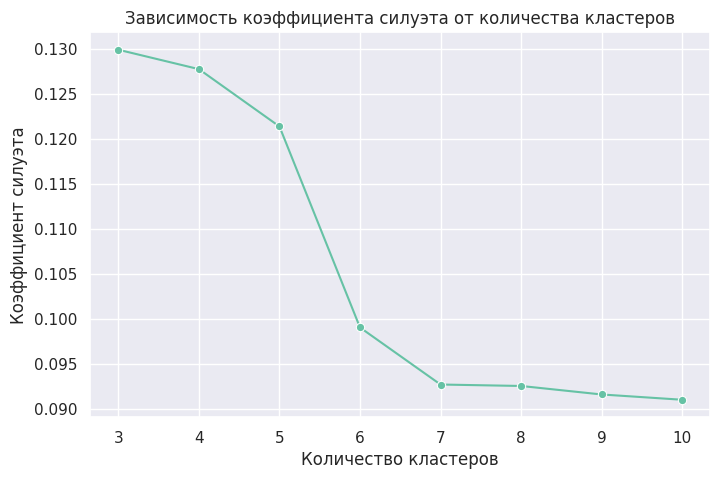

Лучшее количество кластеров среди значений от 3 до 10: 3
Коэффициент силуэта: 0.130


In [22]:
best_index = np.argmax(silhouette_scores)
best_n_clusters = n_clusters_grid[best_index]

plt.figure(figsize=(8, 5))
sns.lineplot(x=list(n_clusters_grid), y=silhouette_scores, marker="o")
plt.xticks(list(n_clusters_grid))
plt.title("Зависимость коэффициента силуэта от количества кластеров")
plt.xlabel("Количество кластеров")
plt.ylabel("Коэффициент силуэта")
plt.show()

print(f"Лучшее количество кластеров среди значений от 3 до 10: {best_n_clusters}")
print(f"Коэффициент силуэта: {silhouette_scores[best_index]:.3f}")


Видим, что среди разбиений от 3 до 10 кластеров максимальный силуэт получается для трех кластеров и составляет примерно $0.130$. Для четырех кластеров значение близкое, около $0.128$, а дальнейшее увеличение количества кластеров его уменьшает. Выберем три кластера. Сам силуэт невысокий, поэтому полученное разбиение не стоит считать набором четко отделенных друг от друга групп.

Отобразим полученное разбиение в проекции на первые две главные компоненты. Номера кластеров сами по себе ничего не означают, поэтому для удобства пронумеруем их от более темных изображений к более светлым.


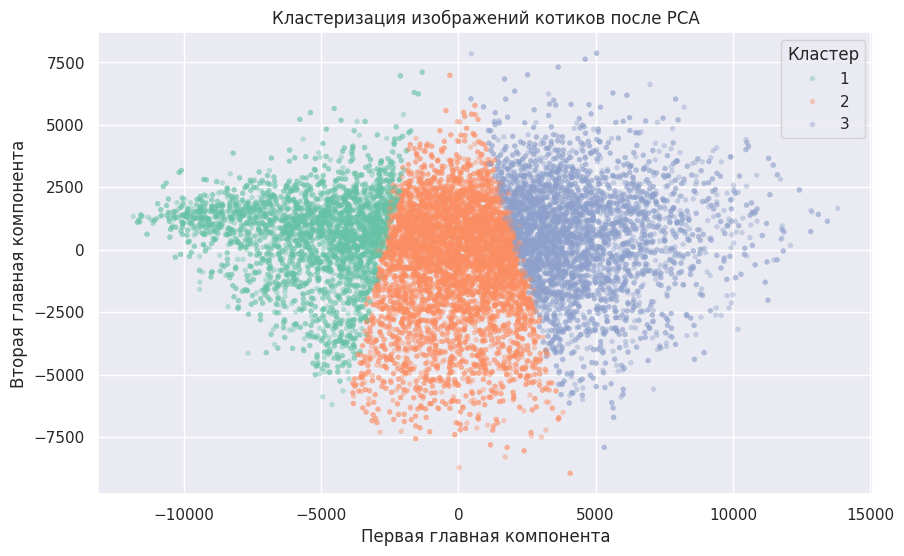

In [23]:
kmeans = kmeans_models[best_n_clusters]
cats_labels = kmeans.labels_

# Упорядочиваем номера кластеров по средней яркости исходных изображений
cluster_brightness = [
    cats[cats_labels == cluster].mean() for cluster in range(best_n_clusters)
]
cluster_order = np.argsort(cluster_brightness)
cats_labels = np.argsort(cluster_order)[cats_labels]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=cats_projection[:, 0],
    y=cats_projection[:, 1],
    hue=cats_labels + 1,
    palette=sns.color_palette("Set2", best_n_clusters),
    s=15,
    alpha=0.4,
    linewidth=0,
)
plt.title("Кластеризация изображений котиков после PCA")
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend(title="Кластер")
plt.show()


Теперь посмотрим несколько исходных изображений из каждого кластера. Выберем их случайно с фиксированным `random_state`, чтобы при повторном запуске получить те же примеры.


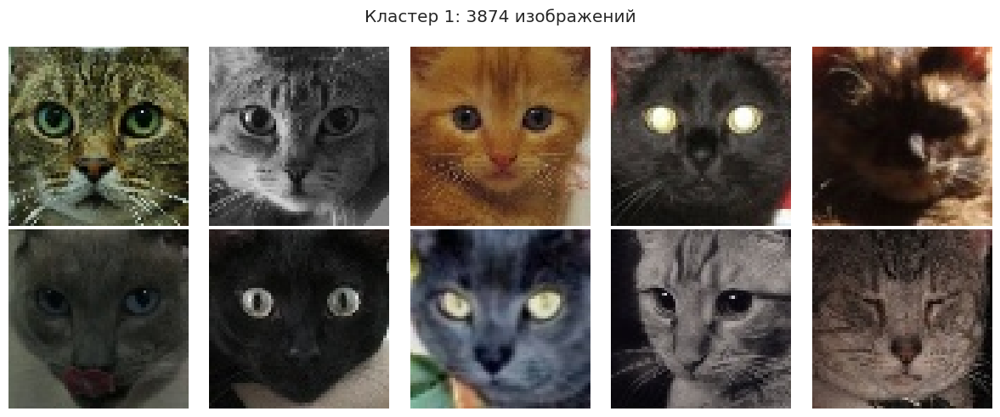

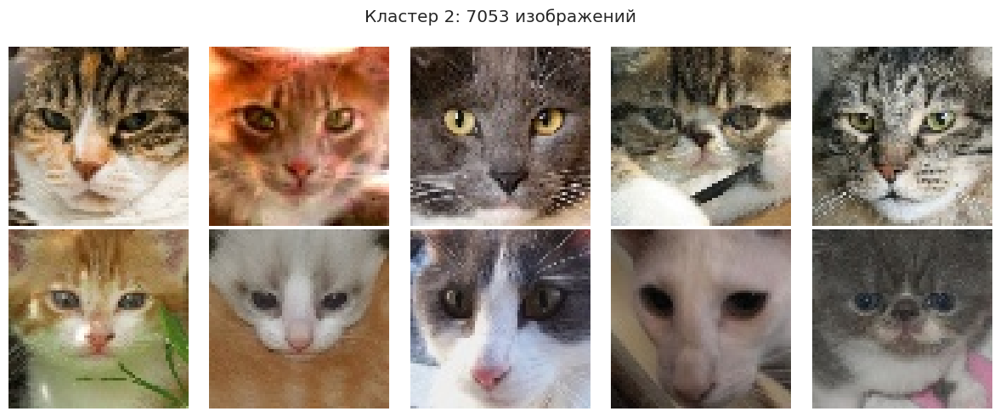

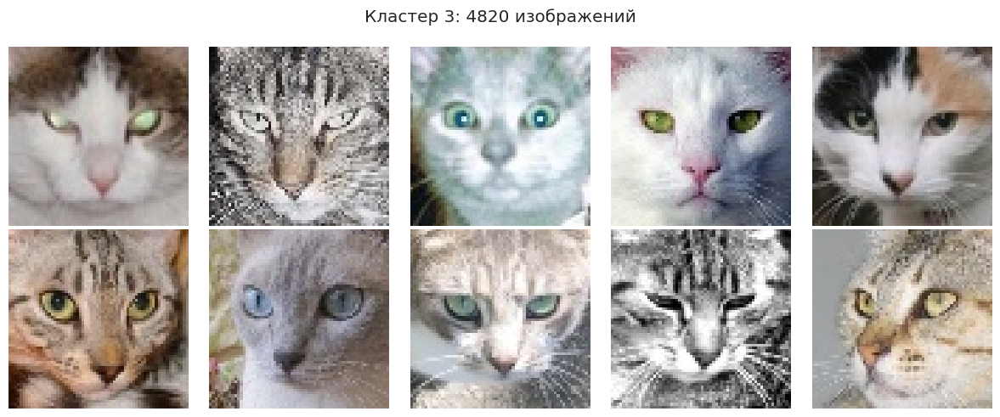

In [24]:
rng = np.random.RandomState(RANDOM_STATE)
num_images = 10

for cluster in range(best_n_clusters):
    indices = np.flatnonzero(cats_labels == cluster)
    example_indices = rng.choice(
        indices, size=min(num_images, len(indices)), replace=False
    )

    plt.figure(figsize=(12, 5))
    plt.suptitle(f"Кластер {cluster + 1}: {len(indices)} изображений")
    for i, image_index in enumerate(example_indices):
        plt.subplot(2, 5, i + 1)
        plt.imshow(cats[image_index].reshape(64, 64, 3))
        plt.axis("off")

    plt.tight_layout()
    plt.show()


Также посмотрим на средние изображения внутри кластеров. Усреднение сглаживает отдельные детали и позволяет лучше увидеть общие различия между группами.


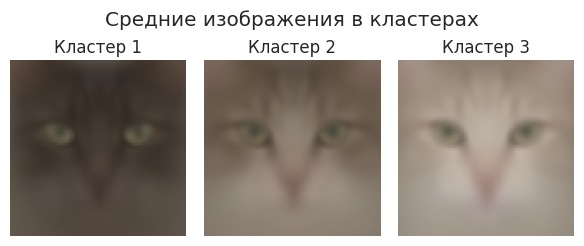

In [25]:
plt.figure(figsize=(2 * best_n_clusters, 2.5))
plt.suptitle("Средние изображения в кластерах")

for cluster in range(best_n_clusters):
    mean_image = cats[cats_labels == cluster].mean(axis=0)
    plt.subplot(1, best_n_clusters, cluster + 1)
    plt.imshow(np.clip(mean_image.reshape(64, 64, 3) / 255, 0, 1))
    plt.title(f"Кластер {cluster + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Можно заметить несколько интересных моментов:
- В первом кластере собраны наиболее темные изображения. Среди примеров много черных и темно-серых котиков, а также полосатых мордочек в тени. На темной шерсти часто хорошо выделяются глаза. При этом сюда попал и рыжий котик, изображение которого в целом получилось темным.
- Во втором кластере изображения имеют промежуточную яркость. На примерах часто видны светлые участки вокруг носа и подбородка при более темных лбе и области вокруг глаз. Здесь встречаются полосатые, рыжие и пятнистые котики, то есть группа достаточно разнообразная по окрасу.
- В третьем кластере изображения в целом наиболее светлые. Видны белые и светло-серые мордочки, а также полосатые котики с большими светлыми участками шерсти. У многих примеров светлая область занимает значительную часть мордочки, иногда хорошо заметен и светлый фон.

На средних изображениях видно постепенное увеличение яркости от первого к третьему кластеру. Второй кластер занимает промежуточное положение: в нем уже выделяются светлые щеки и область вокруг носа, но верхняя часть мордочки остается темнее. То есть в данном случае k-means в первую очередь разделяет изображения по общей яркости и распределению светлых и темных участков. На это влияют как окрас котика, так и освещение и фон.

При этом в разных группах встречаются похожие окрасы и положения головы. Четкого разделения по этим признакам не получилось, что согласуется с невысоким значением силуэта.


<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для DS-потока</div>